In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

import warnings
warnings.simplefilter("ignore")
with warnings.catch_warnings():
    warnings.simplefilter("ignore")

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/extrovert-vs-introvert/submission_example.csv
/kaggle/input/extrovert-vs-introvert/train.csv
/kaggle/input/extrovert-vs-introvert/test.csv


In [2]:
#Reading everything
train_df = pd.read_csv("/kaggle/input/extrovert-vs-introvert/train.csv")
test_df = pd.read_csv("/kaggle/input/extrovert-vs-introvert/test.csv")
combine = [train_df, test_df]
train_df.head()

# Replacing Booleans with 1s and 0s
train_df['Takut_panggung'] = train_df['Takut_panggung'].replace({"Yes": int(1), "No": int(0)})
train_df['Lelah_setelah_bersosialisasi'] = train_df['Lelah_setelah_bersosialisasi'].replace({"Yes": int(1), "No": int(0)})

test_df['Takut_panggung'] = test_df['Takut_panggung'].replace({"Yes": int(1), "No": int(0)})
test_df['Lelah_setelah_bersosialisasi'] = test_df['Lelah_setelah_bersosialisasi'].replace({"Yes": int(1), "No": int(0)})

test_df.head()





,id,Waktu_sendiri_per_hari,Takut_panggung,Frekuensi_hadir_acara_sosial,Frekuensi_keluar_rumah,Lelah_setelah_bersosialisasi,Jumlah_teman_dekat,Frekuensi_posting_medsos
0,441,0.0,0.0,6.0,6.0,0.0,11.0,5.0
1,2693,1.0,0.0,7.0,5.0,0.0,12.0,3.0
2,226,6.0,NaN,0.0,2.0,1.0,1.0,2.0
3,329,2.0,0.0,4.0,6.0,0.0,7.0,3.0
4,1260,3.0,0.0,4.0,6.0,0.0,7.0,8.0


In [3]:
train_df.head()

,id,Waktu_sendiri_per_hari,Takut_panggung,Frekuensi_hadir_acara_sosial,Frekuensi_keluar_rumah,Lelah_setelah_bersosialisasi,Jumlah_teman_dekat,Frekuensi_posting_medsos,Kepribadian
0,400,0.0,0.0,7.0,7.0,0.0,4.0,6.0,Extrovert
1,2896,3.0,0.0,7.0,6.0,0.0,6.0,6.0,Extrovert
2,2024,0.0,0.0,6.0,6.0,0.0,11.0,8.0,Extrovert
3,2614,3.0,0.0,4.0,6.0,0.0,9.0,NaN,Extrovert
4,2690,5.0,1.0,0.0,1.0,1.0,4.0,1.0,Introvert


In [4]:
# Dropping 'id'
train_dropped = train_df.copy()
train_dropped = train_dropped.drop('id', axis=1)
test_dropped = test_df.drop('id', axis = 1)

# Replace null value jadi median
for column in train_dropped.columns:
    if train_dropped[column].isnull().any():
        train_dropped[column].fillna(train_dropped[column].median(), inplace=True)

train_dropped.info()
print('_'*40)

for column in test_dropped.columns:
    if test_dropped[column].isnull().any():
        test_dropped[column].fillna(test_dropped[column].median(), inplace=True)

test_dropped.info()
train_dropped['panggungXlelah'] = train_dropped['Takut_panggung'] * train_dropped['Lelah_setelah_bersosialisasi']
train_dropped.info()
test_dropped['panggungXlelah'] = test_dropped['Takut_panggung'] * test_dropped['Lelah_setelah_bersosialisasi']



<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2320 entries, 0 to 2319
Data columns (total 8 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Waktu_sendiri_per_hari        2320 non-null   float64
 1   Takut_panggung                2320 non-null   float64
 2   Frekuensi_hadir_acara_sosial  2320 non-null   float64
 3   Frekuensi_keluar_rumah        2320 non-null   float64
 4   Lelah_setelah_bersosialisasi  2320 non-null   float64
 5   Jumlah_teman_dekat            2320 non-null   float64
 6   Frekuensi_posting_medsos      2320 non-null   float64
 7   Kepribadian                   2320 non-null   object 
dtypes: float64(7), object(1)
memory usage: 145.1+ KB
________________________________________
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 580 entries, 0 to 579
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        -----------

In [5]:
train_dropped.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2320 entries, 0 to 2319
Data columns (total 9 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Waktu_sendiri_per_hari        2320 non-null   float64
 1   Takut_panggung                2320 non-null   float64
 2   Frekuensi_hadir_acara_sosial  2320 non-null   float64
 3   Frekuensi_keluar_rumah        2320 non-null   float64
 4   Lelah_setelah_bersosialisasi  2320 non-null   float64
 5   Jumlah_teman_dekat            2320 non-null   float64
 6   Frekuensi_posting_medsos      2320 non-null   float64
 7   Kepribadian                   2320 non-null   object 
 8   panggungXlelah                2320 non-null   float64
dtypes: float64(8), object(1)
memory usage: 163.3+ KB


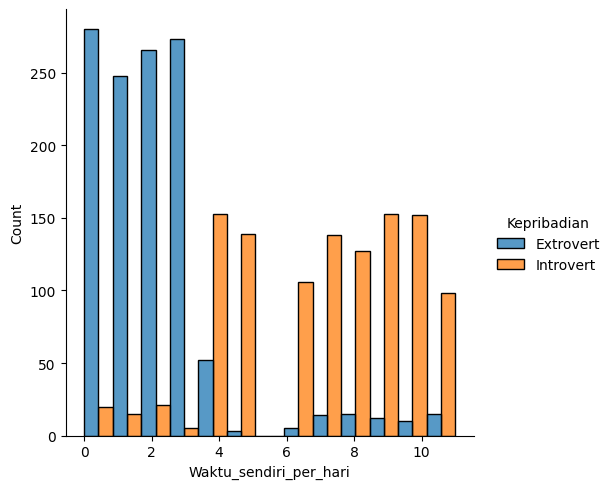

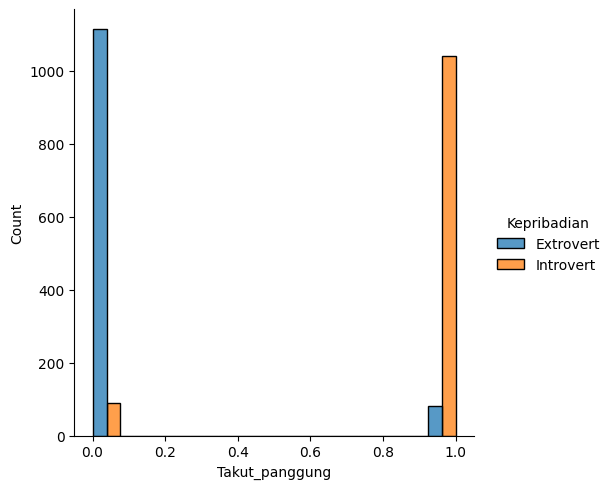

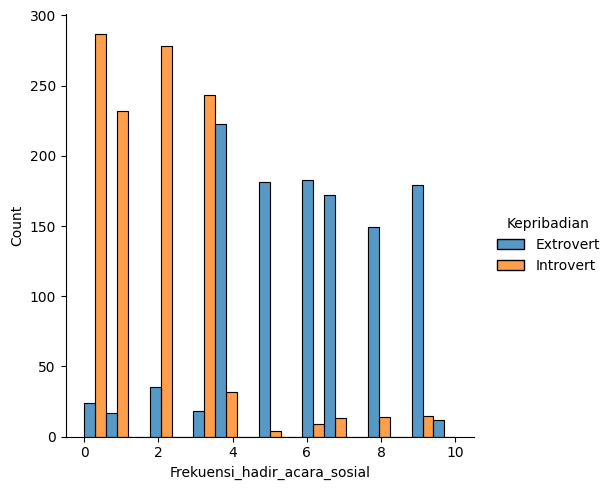

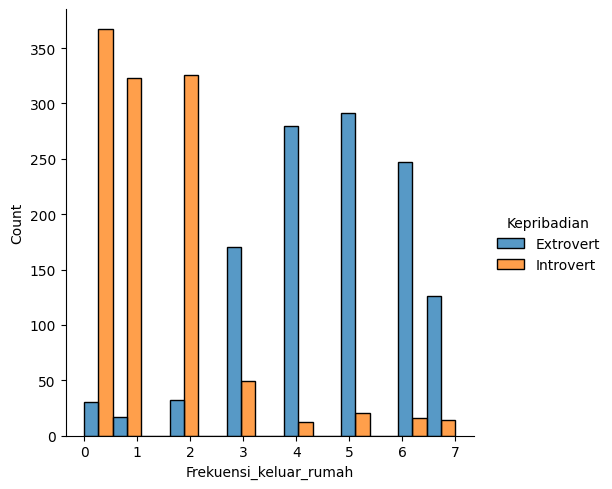

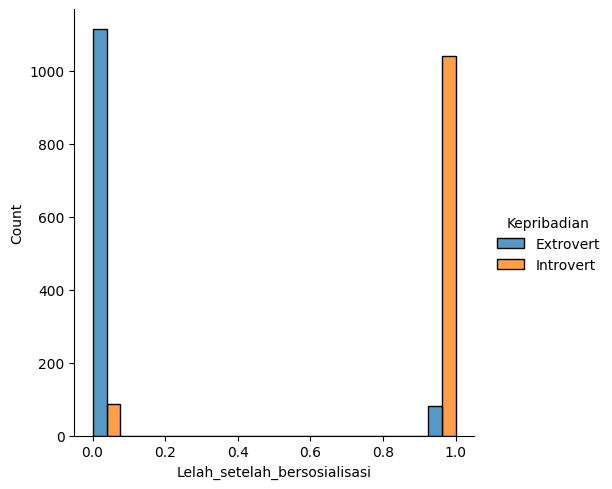

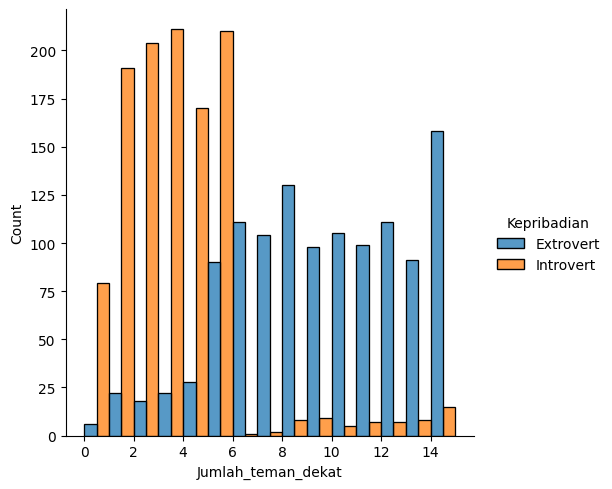

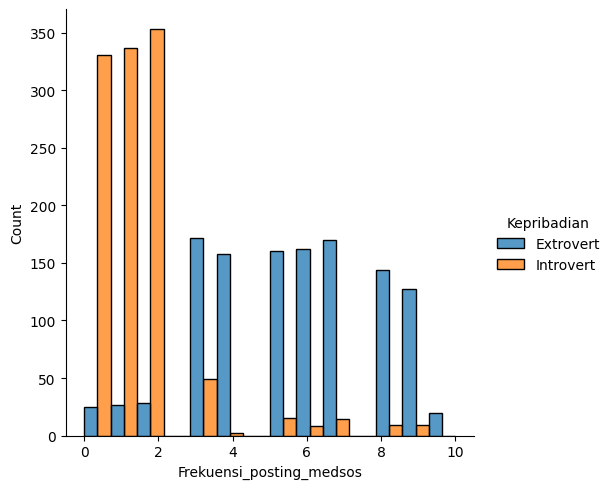

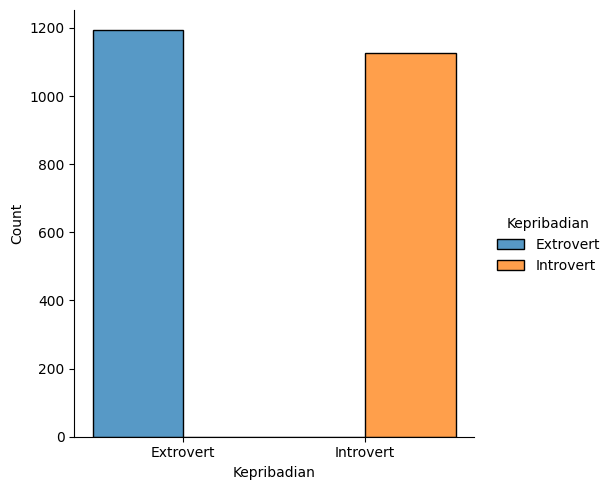

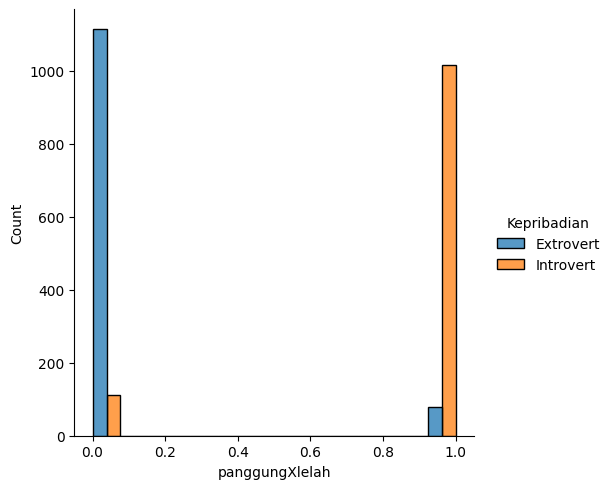

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
for col in train_dropped.columns:
    sns.displot(train_dropped, x= col, hue="Kepribadian", multiple="dodge")




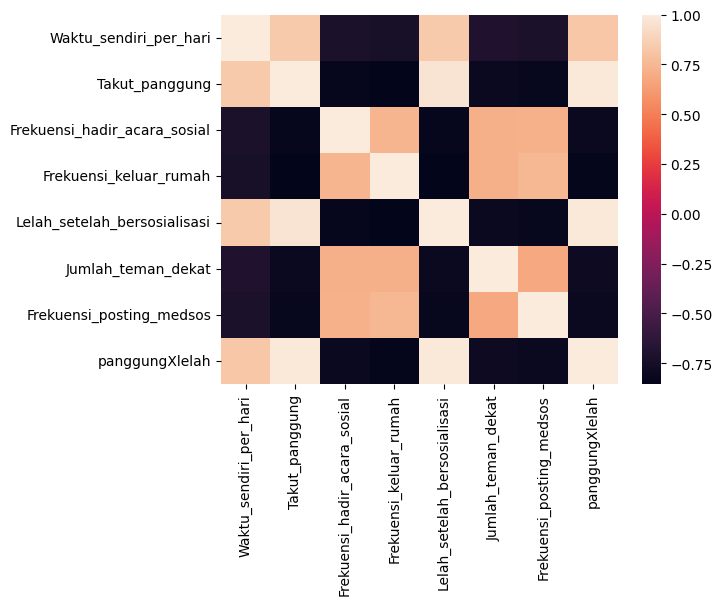

In [7]:
lol = train_dropped.copy()
lol = lol.drop('Kepribadian', axis=1)

sns.heatmap(lol.corr());

In [8]:
# Data Processing
import pandas as pd
import numpy as np

# Modelling
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier 
from sklearn.metrics import accuracy_score, confusion_matrix, precision_score, recall_score, ConfusionMatrixDisplay
from sklearn.model_selection import RandomizedSearchCV, train_test_split
from scipy.stats import randint

# Tree Visualisation
from sklearn.tree import export_graphviz
from IPython.display import Image
import graphviz

In [9]:
train_dropped.columns

Index(['Waktu_sendiri_per_hari', 'Takut_panggung',
       'Frekuensi_hadir_acara_sosial', 'Frekuensi_keluar_rumah',
       'Lelah_setelah_bersosialisasi', 'Jumlah_teman_dekat',
       'Frekuensi_posting_medsos', 'Kepribadian', 'panggungXlelah'],
      dtype='object')

In [10]:
# Split the data into features (X) and target (y)
X_train = train_dropped.drop('Kepribadian', axis=1)
y_train = train_dropped['Kepribadian']

output = [] 

#Storing all the Decision Trees
Column_list = X_train.columns
Column_list = list(Column_list)

for i in X_train.columns:
    for j in X_train.columns:
        if(i==j):
            continue
        Column_list.append([i, j])

for col in Column_list:
    X = X_train[col]
    
    if isinstance(col, list) and len(col) == 2:
        pass
    else:
        X = X.values.reshape(-1, 1)
            
        
    dt = RandomForestClassifier(random_state=42)
    print(len(y_train))
    dt.fit(X, y_train)

    if isinstance(col, list) and len(col) == 2:
        y_pred = dt.predict(test_dropped[col])
    else:
        y_pred = dt.predict(test_dropped[col].values.reshape(-1,1))
    
    output.append(y_pred)
    

len(output)

2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320
2320


64

In [11]:
# Split the data into features (X) and target (y)
X = train_dropped.drop('Kepribadian', axis=1)
Y = train_dropped['Kepribadian']

dt = DecisionTreeClassifier()
model = dt.fit(X, Y)

y_pred = dt.predict(test_dropped)

In [12]:
# Saving model
import joblib

joblib.dump(model, 'dct_model.pkl')

['dct_model.pkl']

In [13]:
# Loading model
dct_model = joblib.load('dct_model.pkl')

In [14]:
new_data = {
    'Waktu_sendiri_per_hari': 5,
    'Takut_panggung': 'Ya',
    'Frekuensi_hadir_acara_sosial': 3,
    'Frekuensi_keluar_rumah': 4,
    'Lelah_setelah_bersosialisasi': 'Tidak',
    'Jumlah_teman_dekat': 7,
    'Frekuensi_posting_medsos': 6,
    
}

In [15]:
from sklearn.preprocessing import LabelEncoder
# Convert to DataFrame
input_df = pd.DataFrame([new_data])

# Encode the categorical features
input_df['Takut_panggung'] = LabelEncoder().fit(['Ya', 'Tidak']).transform(input_df['Takut_panggung'])
input_df['Lelah_setelah_bersosialisasi'] = LabelEncoder().fit(['Ya', 'Tidak']).transform(input_df['Lelah_setelah_bersosialisasi'])
input_df['panggungXlelah'] = input_df["Takut_panggung"]*input_df["Lelah_setelah_bersosialisasi"]
# Predict
prediction = model.predict(input_df)
prediction

array(['Extrovert'], dtype=object)

In [16]:
# Visualizing time~


In [17]:
# Not splitting the data for this one, same as above actually
# Split the data into features (X) and target (y)
X = train_dropped.drop('Kepribadian', axis=1)
y = train_dropped['Kepribadian']

output = [] 

#Storing all the Decision Trees
for col in X.columns:
    X2 = X[col]
    X2 = X2.values.reshape(-1, 1)
    dt = RandomForestClassifier(random_state=42)
    
    dt.fit(X2, y)

    y_pred = dt.predict(test_dropped[col].values.reshape(-1,1))
    output.append(y_pred)
    


In [18]:
#[[1, 2, 3], [1, 2, 3], [1, 2, 3], [1, 2, 3], [1, 2, 3], [1, 2, 3], [1, 2, 3]]

jawaban = []

# 1 sama 4 digabung



for i in range(len(output[0])):
    introv = 0
    extrov = 0
    for j in range(len(output)):   
        expression = output[j][i]
        if (expression=='Introvert'):
            introv += 1
        else:
            extrov += 1

    if(introv>extrov):
        jawaban.append('Introvert')
    else:
        jawaban.append('Extrovert')
    print(introv, extrov)


0 8
0 8
8 0
0 8
0 8
0 8
8 0
8 0
1 7
8 0
0 8
1 7
1 7
0 8
8 0
0 8
0 8
1 7
8 0
8 0
8 0
0 8
0 8
8 0
8 0
8 0
8 0
1 7
1 7
0 8
0 8
0 8
8 0
8 0
1 7
0 8
0 8
1 7
0 8
0 8
8 0
1 7
8 0
8 0
8 0
8 0
0 8
1 7
8 0
8 0
8 0
8 0
0 8
8 0
8 0
0 8
8 0
0 8
0 8
8 0
8 0
7 1
8 0
0 8
0 8
8 0
8 0
8 0
8 0
0 8
0 8
8 0
8 0
8 0
8 0
8 0
0 8
0 8
8 0
8 0
0 8
0 8
8 0
1 7
8 0
8 0
0 8
0 8
8 0
8 0
0 8
8 0
0 8
0 8
1 7
8 0
0 8
8 0
8 0
0 8
8 0
1 7
8 0
8 0
8 0
1 7
8 0
8 0
0 8
8 0
8 0
8 0
8 0
0 8
8 0
8 0
1 7
0 8
8 0
1 7
0 8
8 0
8 0
0 8
0 8
8 0
8 0
8 0
8 0
1 7
1 7
1 7
0 8
8 0
8 0
8 0
1 7
0 8
8 0
1 7
0 8
0 8
0 8
8 0
8 0
1 7
8 0
8 0
8 0
8 0
8 0
7 1
0 8
0 8
1 7
1 7
1 7
8 0
0 8
0 8
0 8
0 8
1 7
0 8
0 8
0 8
8 0
8 0
8 0
8 0
0 8
0 8
8 0
0 8
8 0
8 0
1 7
0 8
8 0
1 7
8 0
0 8
0 8
8 0
8 0
1 7
0 8
0 8
0 8
1 7
1 7
0 8
2 6
8 0
8 0
0 8
1 7
8 0
8 0
0 8
1 7
0 8
8 0
0 8
8 0
8 0
0 8
8 0
8 0
8 0
1 7
8 0
8 0
8 0
1 7
0 8
0 8
0 8
1 7
8 0
8 0
8 0
0 8
0 8
8 0
0 8
1 7
0 8
0 8
1 7
8 0
0 8
8 0
8 0
8 0
1 7
0 8
8 0
8 0
8 0
8 0
8 0
8 0
8 0
8 0
0 8
1 7
0 8
8 0
8 0


In [19]:
submission = pd.read_csv("/kaggle/input/extrovert-vs-introvert/submission_example.csv")
submission['Kepribadian'] = jawaban


In [20]:
submission.to_csv("KDFFinally.csv", index=False)

# GRADIO DEMO YESSIRE!!!

In [21]:
!pip install gradio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 54.3/54.3 MB 33.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.9/323.9 kB 21.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 95.6/95.6 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 92.4 MB/s eta 0:00:00:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.0/72.0 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.4/66.4 kB 3.5 MB/s eta 0:00:00


In [22]:
import gradio as gr
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
import joblib

# --- Optional: Load your trained model from disk if you saved it ---
# model = joblib.load("random_forest_model.pkl")

# --- Dummy model if you want to test without loading ---
# Remove this part if you're using a real model
# model = RandomForestClassifier()
# model.fit(X_train, y_train)

# Label encoding helper
label_enc = LabelEncoder()
label_enc.fit(['Ya', 'Tidak'])

# Mapping back to Ekstrovert/Introvert
# kepribadian_mapping = {0: 'Ekstrovert', 1: 'Introvert'}

def predict_kepribadian(waktu, takut_panggung, hadir, keluar, lelah, teman, medsos):
    # Prepare input
    input_dict = {
        'Waktu_sendiri_per_hari': waktu,
        'Takut_panggung': label_enc.transform([takut_panggung])[0],
        'Frekuensi_hadir_acara_sosial': hadir,
        'Frekuensi_keluar_rumah': keluar,
        'Lelah_setelah_bersosialisasi': label_enc.transform([lelah])[0],
        'Jumlah_teman_dekat': teman,
        'Frekuensi_posting_medsos': medsos
    }
    input_df = pd.DataFrame([input_dict])
    input_df['panggungXlelah'] = input_df["Takut_panggung"] * input_df["Lelah_setelah_bersosialisasi"]

    # Predict
    pred = model.predict(input_df)[0]
    return pred

# Define the Gradio interface
demo = gr.Interface(
    fn=predict_kepribadian,
    inputs=[
        gr.Slider(0, 11, step=1, label="Waktu sendiri per hari"),
        gr.Radio(["Ya", "Tidak"], label="Takut panggung"),
        gr.Slider(0, 10, step=1, label="Frekuensi hadir acara sosial"),
        gr.Slider(0, 7, step=1, label="Frekuensi keluar rumah"),
        gr.Radio(["Ya", "Tidak"], label="Lelah setelah bersosialisasi"),
        gr.Slider(0, 15, step=1, label="Jumlah teman dekat"),
        gr.Slider(0, 10, step=1, label="Frekuensi posting medsos")
    ],
    outputs="text",
    title="(Ekstrovert/Introvert)",
    description="KC Introvert/Extrovert Predictor"
)

# Launch the app
demo.launch()


* Running on local URL:  http://127.0.0.1:7860
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

* Running on public URL: https://87d758d5bf8e550b87.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [23]:
import gradio as gr
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
import joblib

# Load your trained mod
# Label encoding helper (same order as during training)
label_enc = LabelEncoder()
label_enc.fit(['Ya', 'Tidak'])

# Mapping for model output (change if needed to match your label encoding)
kepribadian_mapping = {0: 'Ekstrovert', 1: 'Introvert'}

def predict_kepribadian(waktu, takut_panggung, hadir, keluar, lelah, teman, medsos):
    # Prepare input
    input_dict = {
        'Waktu_sendiri_per_hari': waktu,
        'Takut_panggung': label_enc.transform([takut_panggung])[0],
        'Frekuensi_hadir_acara_sosial': hadir,
        'Frekuensi_keluar_rumah': keluar,
        'Lelah_setelah_bersosialisasi': label_enc.transform([lelah])[0],
        'Jumlah_teman_dekat': teman,
        'Frekuensi_posting_medsos': medsos
    }
    input_df = pd.DataFrame([input_dict])
    input_df['panggungXlelah'] = input_df["Takut_panggung"] * input_df["Lelah_setelah_bersosialisasi"]

    # Predict probabilities
    proba = model.predict_proba(input_df)[0]  # e.g., [0.65, 0.35]
    classes = model.classes_  # e.g., ['Ekstrovert', 'Introvert']

    # Create dict of class probabilities in percentage
    proba_labels = {cls: round(p, 4) for cls, p in zip(classes, proba)}  # floats between 0.0 and 1.0


    # Get the top predicted class
    predicted_class = model.predict(input_df)[0]  # already a string like 'Ekstrovert'

    return predicted_class, proba_labels


# Gradio interface
demo = gr.Interface(
    fn=predict_kepribadian,
    inputs=[
        gr.Slider(0, 11, step=1, label="Waktu sendiri per hari"),
        gr.Radio(["Ya", "Tidak"], label="Takut panggung"),
        gr.Slider(0, 10, step=1, label="Frekuensi hadir acara sosial"),
        gr.Slider(0, 7, step=1, label="Frekuensi keluar rumah"),
        gr.Radio(["Ya", "Tidak"], label="Lelah setelah bersosialisasi"),
        gr.Slider(0, 15, step=1, label="Jumlah teman dekat"),
        gr.Slider(0, 10, step=1, label="Frekuensi posting medsos")
    ],
    outputs=[
        gr.Textbox(label="Prediksi Kepribadian"),
        gr.Label(label="Persentase Probabilitas")
    ],
    title="Prediksi Kepribadian (Ekstrovert / Introvert)",
    description="Masukkan datamu untuk melihat prediksi kepribadianmu berdasarkan model Random Forest."
)

# Launch
demo.launch()


* Running on local URL:  http://127.0.0.1:7861
It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

* Running on public URL: https://b244bb684b7fe863ab.gradio.live

This share link expires in 1 week. For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
